# Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from scipy import signal

# Global parameters
T_rc = 0.01                         # RC clen 1. reda [s]
omega0, K = 10.0, 1.0               # clen 2. reda
zeta_list = [0.1, 0.3, 0.707, 1.0, 1.5]
w_rc = np.logspace(0, 4, 2000)      # rad/s
w_2 = np.logspace(0, 3, 4000)

# Funkcije

In [2]:
# Simbolno: |F(jw)| za clen 2. reda, resonancna frekvenca in visina vrha
w, w0, z, Ks = sp.symbols("omega omega_0 zeta K", positive=True)
s = sp.symbols("s")
T = 1 / w0
F_sym = Ks / (T**2 * s**2 + 2 * z * T * s + 1)
mag2 = sp.simplify(sp.Abs(F_sym.subs(s, sp.I * w))**2)
w_r = sp.solve(sp.diff(1 / mag2, w), w)[0]
M_r = sp.simplify(sp.sqrt(mag2.subs(w, w_r)))

In [3]:
def clen1(T):
    return signal.TransferFunction([1.0], [T, 1.0])

def clen2(zeta, omega0=omega0, K=K):
    T = 1 / omega0
    return signal.TransferFunction([K], [T**2, 2 * zeta * T, 1.0])

def bode_risi(axs, sistem, w, **kw):
    w, mag, ph = signal.bode(sistem, w)
    axs[0].semilogx(w, mag, **kw)
    axs[1].semilogx(w, ph, **kw)
    return w, mag, ph

def oblikuj(axs):
    axs[0].set_ylabel(r"$A_{dB}$ [dB]", fontsize=14)
    axs[1].set_ylabel(r"$\phi$ [$^\circ$]", fontsize=14)
    axs[1].set_xlabel(r"$\omega$ [rad/s]", fontsize=14)
    for ax in axs:
        ax.grid(alpha=0.3, which="both")

# Testno območje

In [4]:
# Pripravljalna naloga
display(sp.Eq(sp.Symbol(r"\omega_r"), w_r), sp.Eq(sp.Symbol("M_r"), M_r))
Mr_02 = float(M_r.subs({Ks: 1, z: sp.Rational(1, 5)}))
print(f"zeta = 0.2: |F(j w_r)| = {Mr_02:.4f} = {20 * np.log10(Mr_02):.2f} dB")
faza_w0 = sp.arg(F_sym.subs({s: sp.I * w0, Ks: 1}))
print("faza pri omega = omega_0:", sp.simplify(faza_w0), "=", float(sp.deg(sp.simplify(faza_w0))), "st.")

Eq(\omega_r, omega_0*sqrt(1 - 2*zeta**2))

Eq(M_r, K*sqrt(-1/(zeta**2 - 1))/(2*zeta))

zeta = 0.2: |F(j w_r)| = 2.5516 = 8.14 dB
faza pri omega = omega_0: -pi/2 = -90.0 st.


# Naloga 1

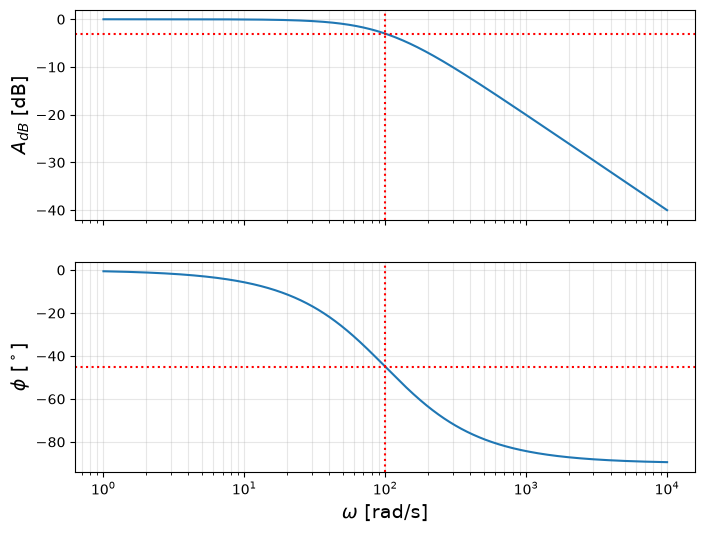

omega_c = 100 rad/s: A = -3.010 dB, phi = -45.00 st.


In [5]:
fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
w_, mag, ph = bode_risi(axs, clen1(T_rc), w_rc)
w_c = 1 / T_rc
for ax, val in zip(axs, [-3.0, -45.0]):
    ax.axvline(w_c, color="red", linestyle=":")
    ax.axhline(val, color="red", linestyle=":")
oblikuj(axs)
plt.show()

_, m_c, p_c = signal.bode(clen1(T_rc), [w_c])
print(f"omega_c = {w_c:.0f} rad/s: A = {m_c[0]:.3f} dB, phi = {p_c[0]:.2f} st.")

# Naloga 2

  zeta   w_r num    w_r an  M_r num [dB]  M_r an [dB]
 0.100     9.897     9.899        14.023       14.023
 0.300     9.062     9.055         4.847        4.847
 0.707  ni resonancnega vrha (A_dB monotono pada, max = -0.0004 dB pri najnizji omega)
 1.000  ni resonancnega vrha (A_dB monotono pada, max = -0.0864 dB pri najnizji omega)
 1.500  ni resonancnega vrha (A_dB monotono pada, max = -0.2942 dB pri najnizji omega)


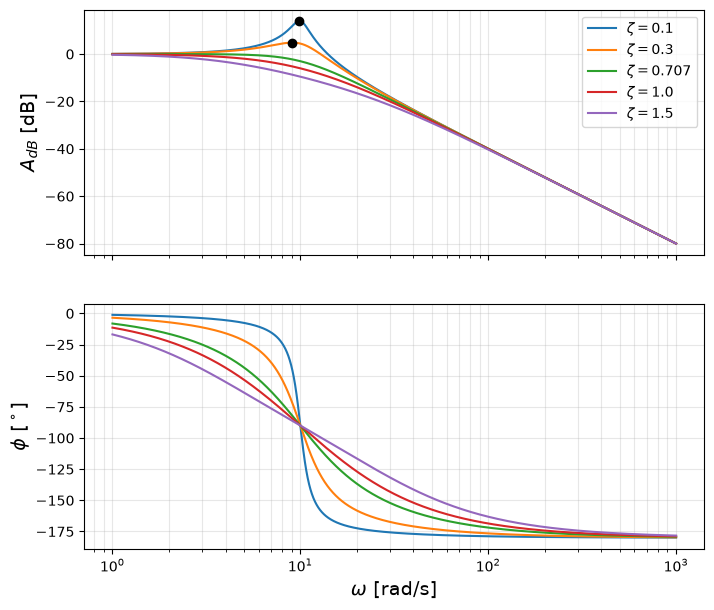

In [6]:
fig, axs = plt.subplots(2, 1, figsize=(8, 7), sharex=True)
print(f"{'zeta':>6} {'w_r num':>9} {'w_r an':>9} {'M_r num [dB]':>13} {'M_r an [dB]':>12}")
for zeta in zeta_list:
    w_, mag, ph = bode_risi(axs, clen2(zeta), w_2, label=rf"$\zeta = {zeta}$")
    i = np.argmax(mag)
    if zeta < 1 / np.sqrt(2) and mag[i] > 1e-6:
        wr_an = omega0 * np.sqrt(1 - 2 * zeta**2)
        Mr_an = 20 * np.log10(1 / (2 * zeta * np.sqrt(1 - zeta**2)))
        axs[0].plot(w_[i], mag[i], "o", color="black")
        print(f"{zeta:6.3f} {w_[i]:9.3f} {wr_an:9.3f} {mag[i]:13.3f} {Mr_an:12.3f}")
    else:
        print(f"{zeta:6.3f}  ni resonancnega vrha (A_dB monotono pada, max = {mag.max():.4f} dB pri najnizji omega)")
axs[0].legend()
oblikuj(axs)
plt.show()

# Naloga 3

  zeta  prenihaj [%]   exp(-pi z/sqrt(1-z^2)) [%]     M_r
 0.100         72.92                        72.92   5.025
 0.300         37.23                        37.23   1.747
 0.707          4.33                         4.33   1.000
 1.000          0.00                         0.00   1.000
 1.500          0.00                         0.00   1.000


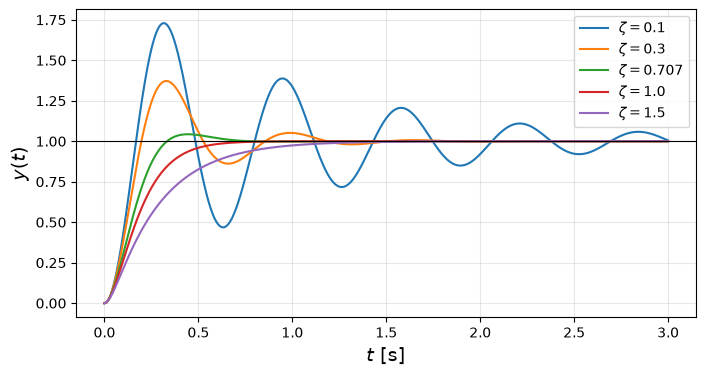

In [7]:
t = np.linspace(0, 3, 3000)
fig = plt.figure(figsize=(8, 4))
ax = fig.add_subplot(111)
print(f"{'zeta':>6} {'prenihaj [%]':>13} {'exp(-pi z/sqrt(1-z^2)) [%]':>28} {'M_r':>7}")
for zeta in zeta_list:
    t_, y = signal.step(clen2(zeta), T=t)
    ax.plot(t_, y, label=rf"$\zeta = {zeta}$")
    Mp = 100 * max(y.max() - 1, 0)
    Mp_an = 100 * np.exp(-np.pi * zeta / np.sqrt(1 - zeta**2)) if zeta < 1 else 0.0
    Mr = 1 / (2 * zeta * np.sqrt(1 - zeta**2)) if zeta < 1 / np.sqrt(2) else 1.0
    print(f"{zeta:6.3f} {Mp:13.2f} {Mp_an:28.2f} {Mr:7.3f}")
ax.axhline(1, color="black", linewidth=0.8)
ax.set_xlabel("$t$ [s]", fontsize=14)
ax.set_ylabel("$y(t)$", fontsize=14)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Razmislek 1

zeta = 0.1: poli = [-1.+9.95j -1.-9.95j],  oddaljenost od osi j*omega = 1.000
zeta = 0.3: poli = [-3.+9.539j -3.-9.539j],  oddaljenost od osi j*omega = 3.000
zeta = 0.707: poli = [-7.07+7.072j -7.07-7.072j],  oddaljenost od osi j*omega = 7.070
zeta = 1.0: poli = [-10.+0.j -10.-0.j],  oddaljenost od osi j*omega = 10.000
zeta = 1.5: poli = [-26.18  -3.82],  oddaljenost od osi j*omega = 3.820


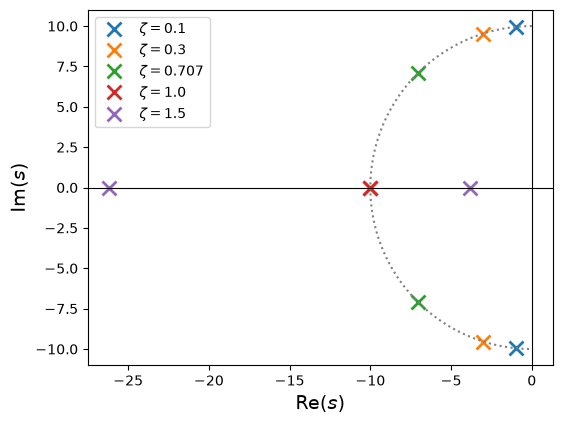

In [8]:
# Poli: s = -zeta w0 +- j w0 sqrt(1 - zeta^2)
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111)
for zeta in zeta_list:
    p = clen2(zeta).poles
    ax.plot(p.real, p.imag, "x", markersize=10, mew=2, label=rf"$\zeta = {zeta}$")
    print(f"zeta = {zeta}: poli = {np.round(p, 3)},  oddaljenost od osi j*omega = {abs(p.real).min():.3f}")
fi = np.linspace(np.pi / 2, 3 * np.pi / 2, 100)
ax.plot(omega0 * np.cos(fi), omega0 * np.sin(fi), ":", color="gray")
ax.axvline(0, color="black", linewidth=0.8)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel(r"Re$(s)$", fontsize=14)
ax.set_ylabel(r"Im$(s)$", fontsize=14)
ax.set_aspect("equal")
ax.legend()
plt.show()

# Razmislek 2

In [9]:
# Asimptotski naklon pri visokih frekvencah [dB/dekado]
for ime, sis, w_hi in [("1. red", clen1(T_rc), [1e5, 1e6]), ("2. red", clen2(0.3), [1e4, 1e5])]:
    _, mag, _ = signal.bode(sis, w_hi)
    print(f"{ime}: {mag[1] - mag[0]:.2f} dB/dekado")

1. red: -20.00 dB/dekado
2. red: -40.00 dB/dekado
